# Healthcare Claims & Clinical Analytics
**Question:** Where does healthcare spending go, who pays for it, and which patients drive cost and readmissions?

**Data:** [Synthea](https://synthetichealth.github.io/synthea/) synthetic patient records: 18 related tables covering patients, encounters, diagnoses, lab results, medications, providers, payers and insurance claims (~200K rows). The data is synthetic, so there are no real patients, but the structure matches the EHR and claims data used in hospital analytics.

**Tools:** SQL (DuckDB): multi-table JOINs, CTEs, `LEAD` / `NTILE` / window aggregates, conditional aggregation · Python: pandas, matplotlib

## Setup

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

DB = "data/healthcare.duckdb"   # built by setup_data.py
con = duckdb.connect(DB, read_only=True)

def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.sql(sql).df()

# Chart style: one blue for single-series charts, quiet axes and grid
BLUE, INK, MUTED, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe8",
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "figure.dpi": 110,
})
pd.set_option("display.max_columns", 20)
q("SHOW TABLES")

,name
0,allergies
1,careplans
2,claims
3,claims_transactions
4,conditions
5,devices
6,encounters
7,imaging_studies
8,immunizations
9,medications


## 1. Care setting volume and cost
Where does the money go? Volume and cost by care setting.

In [2]:
df = q("""
SELECT ENCOUNTERCLASS                   AS care_setting,
       COUNT(*)                         AS encounters,
       ROUND(AVG(TOTAL_CLAIM_COST), 0)  AS avg_cost,
       ROUND(SUM(TOTAL_CLAIM_COST), 0)  AS total_cost,
       ROUND(100 * SUM(TOTAL_CLAIM_COST) / SUM(SUM(TOTAL_CLAIM_COST)) OVER (), 1) AS pct_of_spend
FROM encounters
GROUP BY ENCOUNTERCLASS
ORDER BY total_cost DESC
""")
df

,care_setting,encounters,avg_cost,total_cost,pct_of_spend
0,ambulatory,2446,4133.0,10109417.0,67.5
1,wellness,1239,1313.0,1627116.0,10.9
2,outpatient,855,1559.0,1332827.0,8.9
3,emergency,195,4110.0,801501.0,5.4
4,inpatient,81,7940.0,643124.0,4.3
5,urgentcare,172,1098.0,188826.0,1.3
6,snf,11,16309.0,179404.0,1.2
7,hospice,7,9936.0,69555.0,0.5
8,home,26,590.0,15335.0,0.1
9,virtual,27,232.0,6256.0,0.0


**Finding:** Ambulatory (clinic) care is about two-thirds of total spend. That's because of volume: inpatient and skilled-nursing stays cost far more *per visit*, but they're rare.

## 2. Payer mix
Which insurers carry the most cost, and what share of billed cost do they actually cover?

In [3]:
df = q("""
SELECT p.NAME                                                       AS payer,
       COUNT(*)                                                     AS encounters,
       ROUND(SUM(e.TOTAL_CLAIM_COST), 0)                            AS billed,
       ROUND(SUM(e.PAYER_COVERAGE), 0)                              AS paid_by_payer,
       ROUND(100 * SUM(e.PAYER_COVERAGE) / SUM(e.TOTAL_CLAIM_COST), 1) AS pct_covered
FROM encounters e
JOIN payers p ON e.PAYER = p.Id
GROUP BY p.NAME
HAVING COUNT(*) > 100
ORDER BY billed DESC
""")
df

,payer,encounters,billed,paid_by_payer,pct_covered
0,Medicare,1111,2706010.0,2140296.0,79.1
1,UnitedHealthcare,587,2137014.0,1739056.0,81.4
2,Humana,624,2029054.0,1134849.0,55.9
3,Medicaid,593,1620915.0,1584741.0,97.8
4,Aetna,552,1564000.0,1021071.0,65.3
5,Blue Cross Blue Shield,379,1494960.0,1027127.0,68.7
6,NO_INSURANCE,421,1350765.0,0.0,0.0
7,Cigna Health,422,1177373.0,803597.0,68.3
8,Anthem,217,634115.0,498739.0,78.7
9,Dual Eligible,153,259153.0,254673.0,98.3


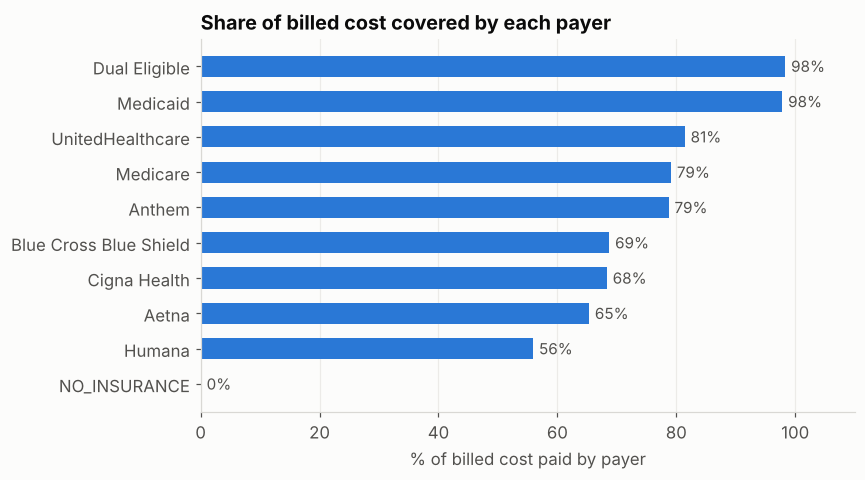

In [4]:
d = df.sort_values("pct_covered")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(d["payer"], d["pct_covered"], color=BLUE, height=0.6)
for y, v in enumerate(d["pct_covered"]):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", color=MUTED, fontsize=10)
ax.set_title("Share of billed cost covered by each payer")
ax.set_xlabel("% of billed cost paid by payer"); ax.set_xlim(0, 110); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/payer_coverage.png", dpi=150); plt.show()

**Finding:** Coverage varies a lot by payer. Medicaid and dual-eligible plans cover ~98% of billed cost, while Humana covers ~56%, which leaves a large patient-responsibility balance. Uninsured encounters are 100% patient responsibility.

## 3. Most common diagnoses
Top clinical diagnoses by number of patients (excluding social 'findings').

In [5]:
df = q("""
SELECT DESCRIPTION AS diagnosis, COUNT(DISTINCT PATIENT) AS patients
FROM conditions
WHERE DESCRIPTION LIKE '%(disorder)'
GROUP BY DESCRIPTION
ORDER BY patients DESC
LIMIT 10
""")
df

,diagnosis,patients
0,Gingivitis (disorder),86
1,Viral sinusitis (disorder),68
2,Acute viral pharyngitis (disorder),49
3,Gingival disease (disorder),46
4,Primary dental caries (disorder),43
5,Acute bronchitis (disorder),38
6,Anemia (disorder),23
7,Essential hypertension (disorder),16
8,Streptococcal sore throat (disorder),15
9,Fracture of bone (disorder),15


**Finding:** Dental and acute respiratory conditions dominate by patient count. Chronic conditions like hypertension affect fewer patients but drive ongoing cost.

## 4. Provider workload
Which providers and facilities handle the most encounters? (3-table join)

In [6]:
df = q("""
SELECT pr.NAME AS provider, pr.SPECIALITY AS specialty, o.NAME AS organization, COUNT(*) AS encounters
FROM encounters e
JOIN providers pr    ON e.PROVIDER = pr.Id
JOIN organizations o ON pr.ORGANIZATION = o.Id
GROUP BY ALL
ORDER BY encounters DESC
LIMIT 10
""")
df

,provider,specialty,organization,encounters
0,Adrienne302 Schiller186,GENERAL PRACTICE,ARBOUR-FULLER HOSPITAL,259
1,Manuela585 Rendón540,GENERAL PRACTICE,Fitchburg Outpatient Clinic,239
2,Alysha630 Koch169,GENERAL PRACTICE,TEWKSBURY HOSPITAL,190
3,Emilia403 Hernández971,GENERAL PRACTICE,TUFTS MEDICAL CENTER INC,128
4,Latoyia537 Lindgren255,GENERAL PRACTICE,DR SOLOMON CARTER FULLER MENTAL HEALTH CENTER,125
5,Deandre599 Windler79,GENERAL PRACTICE,Framingham Outpatient Clinic,122
6,Landon622 Kihn564,GENERAL PRACTICE,WOONSOCKET URGENT CARE PC,121
7,Gregg522 Willms744,GENERAL PRACTICE,MARLBOROUGH HOSPITAL CORP,116
8,Clifton91 Lakin515,GENERAL PRACTICE,4499 ACUSHNET AVENUE OPERATING COMPANY LLC,114
9,Otha286 Roberts511,GENERAL PRACTICE,NEW ENGLAND REHABILITATION SERVICES OF CENTRAL...,111


**Finding:** Patient volume is concentrated in a handful of general-practice providers. A view like this is the starting point for staffing and capacity planning.

## 5. Emergency visit trend
How has emergency department volume changed year over year?

In [7]:
df = q("""
SELECT year(START) AS year, COUNT(*) AS er_visits
FROM encounters
WHERE ENCOUNTERCLASS = 'emergency' AND year(START) BETWEEN 2015 AND 2025
GROUP BY year
ORDER BY year
""")
df

,year,er_visits
0,2015,2
1,2016,4
2,2017,8
3,2018,17
4,2019,19
5,2020,16
6,2021,21
7,2022,9
8,2023,10
9,2024,17


**Finding:** ER volume is noisy at this sample size (~110 patients). A real analysis would normalize per 1,000 patients before calling it a trend.

## 6. 30-day readmission rate
Medicare penalizes hospitals when patients return within 30 days of discharge. What is our inpatient readmission rate? (LEAD window function)

In [8]:
df = q("""
WITH stays AS (
    SELECT PATIENT, START, STOP,
           LEAD(START) OVER (PARTITION BY PATIENT ORDER BY START) AS next_admit
    FROM encounters
    WHERE ENCOUNTERCLASS = 'inpatient'
)
SELECT COUNT(*) AS inpatient_stays,
       COUNT(*) FILTER (WHERE next_admit <= STOP + INTERVAL 30 DAY) AS readmissions_30d,
       ROUND(100.0 * COUNT(*) FILTER (WHERE next_admit <= STOP + INTERVAL 30 DAY) / COUNT(*), 1) AS readmit_rate_pct
FROM stays
""")
df

,inpatient_stays,readmissions_30d,readmit_rate_pct
0,81,5,6.2


**Finding:** The 30-day readmission rate was about 6% of inpatient stays. `LEAD()` pairs each stay with the patient's *next* admission, which is the same logic behind CMS's Hospital Readmissions Reduction Program measure.

## 7. High-cost patient concentration
How concentrated is spending? Share of total cost from the top 10% of patients. (NTILE window function)

In [9]:
df = q("""
WITH per_patient AS (
    SELECT PATIENT, SUM(TOTAL_CLAIM_COST) AS total_cost
    FROM encounters GROUP BY PATIENT
),
ranked AS (
    SELECT *, NTILE(10) OVER (ORDER BY total_cost DESC) AS decile FROM per_patient
)
SELECT decile,
       COUNT(*)                                                  AS patients,
       ROUND(SUM(total_cost), 0)                                 AS total_cost,
       ROUND(100 * SUM(total_cost) / SUM(SUM(total_cost)) OVER (), 1) AS pct_of_spend
FROM ranked
GROUP BY decile
ORDER BY decile
""")
df

,decile,patients,total_cost,pct_of_spend
0,1,12,5985755.0,40.0
1,2,11,2727872.0,18.2
2,3,11,1951292.0,13.0
3,4,11,1339291.0,8.9
4,5,11,954124.0,6.4
5,6,11,723232.0,4.8
6,7,11,516512.0,3.4
7,8,11,382136.0,2.6
8,9,11,265914.0,1.8
9,10,11,127231.0,0.8


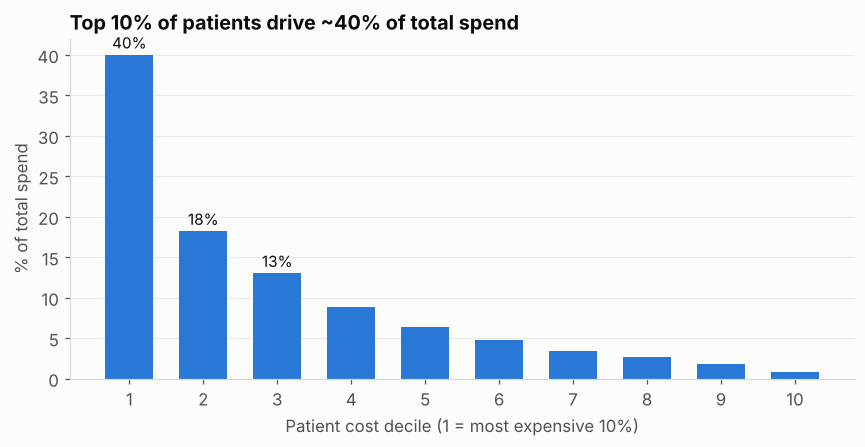

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(df["decile"].astype(str), df["pct_of_spend"], color=BLUE, width=0.65)
for x, v in enumerate(df["pct_of_spend"][:3]):
    ax.text(x, v + 0.8, f"{v:.0f}%", ha="center", color=INK, fontsize=10)
ax.set_title("Top 10% of patients drive ~40% of total spend")
ax.set_xlabel("Patient cost decile (1 = most expensive 10%)"); ax.set_ylabel("% of total spend")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("images/spend_concentration.png", dpi=150); plt.show()

**Finding:** **The top 10% of patients account for ~40% of all spending**, and the top 20% for ~58%. This concentration is why care-management programs target high-cost patients first.

## 8. Diabetes cohort analysis
Compare Type 2 diabetes, prediabetes, and other patients on HbA1c lab values and cost. (multi-CTE cohort build)

In [11]:
df = q("""
WITH flags AS (
    SELECT PATIENT,
           BOOL_OR(DESCRIPTION = 'Diabetes mellitus type 2 (disorder)') AS has_t2d,
           BOOL_OR(DESCRIPTION = 'Prediabetes (finding)')               AS has_prediabetes
    FROM conditions GROUP BY PATIENT
),
a1c AS (
    SELECT PATIENT, AVG(TRY_CAST(VALUE AS DOUBLE)) AS avg_a1c
    FROM observations
    WHERE DESCRIPTION LIKE 'Hemoglobin A1c%'
    GROUP BY PATIENT
),
cost AS (
    SELECT PATIENT, SUM(TOTAL_CLAIM_COST) AS total_cost FROM encounters GROUP BY PATIENT
)
SELECT CASE WHEN f.has_t2d THEN '1 - Type 2 diabetes'
            WHEN f.has_prediabetes THEN '2 - Prediabetes'
            ELSE '3 - Neither' END        AS cohort,
       COUNT(*)                           AS patients,
       ROUND(AVG(a.avg_a1c), 2)           AS avg_a1c_pct,
       ROUND(AVG(c.total_cost), 0)        AS avg_cost_per_patient
FROM patients p
LEFT JOIN flags f ON p.Id = f.PATIENT
LEFT JOIN a1c   a ON p.Id = a.PATIENT
LEFT JOIN cost  c ON p.Id = c.PATIENT
GROUP BY cohort
ORDER BY cohort
""")
df

,cohort,patients,avg_a1c_pct,avg_cost_per_patient
0,1 - Type 2 diabetes,6,5.77,195828.0
1,2 - Prediabetes,27,6.09,129915.0
2,3 - Neither,78,5.44,131932.0


**Finding:** Diabetic patients cost ~50% more per patient than everyone else. Interestingly, their average HbA1c is *lower* than the prediabetes group's. That's likely a treatment effect: diagnosed patients are on medication, and the average spans years of readings. A next step would be comparing A1c before vs. after diagnosis date.

## Python cross-check: readmission rate in pandas
Re-computing the 30-day readmission rate with pandas instead of SQL. `groupby().shift(-1)` is pandas' version of `LEAD()`. It should match the SQL result exactly.

In [12]:
enc = q("SELECT PATIENT, START, STOP FROM encounters WHERE ENCOUNTERCLASS = 'inpatient'")
enc = enc.sort_values(["PATIENT", "START"])
enc["next_admit"] = enc.groupby("PATIENT")["START"].shift(-1)
enc["readmit"] = enc["next_admit"] <= enc["STOP"] + pd.Timedelta(days=30)
print(f"Stays: {len(enc)} | 30-day readmissions: {enc['readmit'].sum()} | Rate: {100 * enc['readmit'].mean():.1f}%")

Stays: 81 | 30-day readmissions: 5 | Rate: 6.2%
